# Pitch Tunneling Analyzer: from trajectories to tunnel features

Runs offline on the packaged sample (1,300 real pitches from four 2023 games). Results from the full 2023 and 2024 seasons are in `reports/` and the README.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from tunneling import sources, integrity, pairs
from tunneling.kinematics import position_at_y, reconstruction_error, PLATE_FRONT_Y

raw = sources.load_sample()
clean, report = integrity.clean(raw)
print(report)

{'rows_in': 1300, 'rows_out': 1281, 'duplicate_key': 0, 'missing_kinematics': 19, 'impossible_speed': 0, 'impossible_plate_x': 0, 'impossible_plate_z': 0, 'bad_zone_bounds': 0, 'trajectory_mismatch': 0}


## 1. Can the trajectory be rebuilt?

Every tunnel feature depends on rebuilding where a pitch was 23.8 feet from the plate, from the release point and the fitted velocity and acceleration. The check: rebuild where each pitch crosses the front of the plate and compare with Statcast's `plate_x`, `plate_z`.

count    1281.000
mean        0.047
std         0.017
min         0.001
25%         0.035
50%         0.048
75%         0.060
max         0.087
Name: recon_err_in, dtype: float64


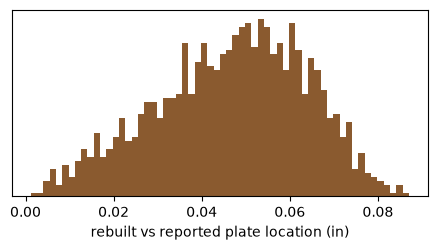

In [2]:
err = reconstruction_error(clean)
print(err.describe().round(3))
fig, ax = plt.subplots(figsize=(4.5, 2.6)); ax.hist(err.clip(0, 1), bins=60, color='#8a5a2f')
ax.set_xlabel('rebuilt vs reported plate location (in)'); ax.set_yticks([]); fig.tight_layout(); plt.show()

## 2. One pair, drawn

A fastball and the slider that followed it, from release to the plate. The vertical line marks the commit point.

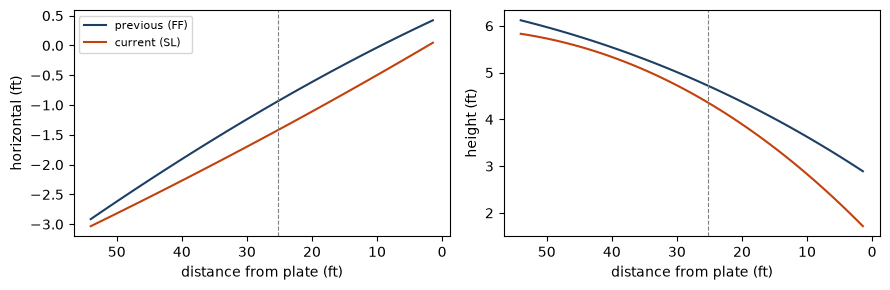

commit separation 7.3 in, plate separation 14.8 in, tunnel ratio 2.04


In [3]:
scored = pairs.score_pairs(pairs.build_pairs(clean))
ex = scored[(scored['prev_pitch_type'] == 'FF') & (scored['pitch_type'] == 'SL')].iloc[0]
cur = pd.DataFrame([ex[['release_pos_x','release_pos_y','release_pos_z','vx0','vy0','vz0','ax','ay','az']]])
prev = pd.DataFrame([{c: ex['prev_' + c] for c in ['release_pos_x','release_pos_y','release_pos_z','vx0','vy0','vz0','ax','ay','az']}])
ys = np.linspace(54, PLATE_FRONT_Y, 60)
path = lambda f: np.array([[v[0] for v in position_at_y(f, y)] for y in ys])
pp, pc = path(prev), path(cur)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
for ax, k, lab in zip(axes, (0, 1), ('horizontal (ft)', 'height (ft)')):
    ax.plot(ys, pp[:, k], label='previous (FF)', color='#1d3f63'); ax.plot(ys, pc[:, k], label='current (SL)', color='#c2410c')
    ax.axvline(PLATE_FRONT_Y + 23.8, color='grey', ls='--', lw=0.8); ax.invert_xaxis(); ax.set_xlabel('distance from plate (ft)'); ax.set_ylabel(lab)
axes[0].legend(fontsize=8); fig.tight_layout(); plt.show()
print('commit separation %.1f in, plate separation %.1f in, tunnel ratio %.2f' % (ex['commit_sep_in'], ex['plate_sep_in'], ex['tunnel_ratio']))

## 3. The derived features

Distributions of commit-point separation, plate separation and the velocity drop. Plate separation should be larger than commit separation for most pairs (pitches diverge toward the plate), and the two are strongly related, which is why the model uses both rather than a ratio.

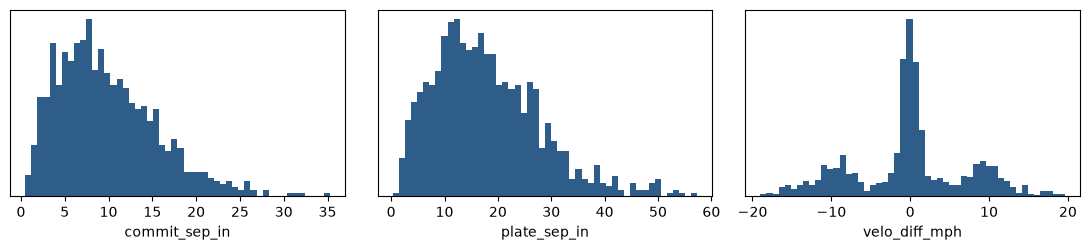

       commit_sep_in  plate_sep_in  tunnel_ratio  velo_diff_mph
count         958.00        958.00        958.00         958.00
mean            9.83         18.04          2.10          -0.23
std             5.64         10.09          1.60           7.29
min             0.49          0.31          0.20         -19.00
25%             5.52         10.59          1.56          -3.62
50%             8.88         16.49          1.81           0.00
75%            13.27         24.05          2.21           2.77
max            35.24         57.35         27.52          19.60
share with plate separation > commit separation: 0.926
correlation commit vs plate separation: 0.78


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(11, 2.6))
for ax, col, hi in zip(axes, ['commit_sep_in', 'plate_sep_in', 'velo_diff_mph'], [40, 60, 30]):
    ax.hist(scored[col].clip(upper=hi), bins=50, color='#2f5d8a'); ax.set_xlabel(col); ax.set_yticks([])
fig.tight_layout(); plt.show()
print(scored[['commit_sep_in', 'plate_sep_in', 'tunnel_ratio', 'velo_diff_mph']].describe().round(2))
print('share with plate separation > commit separation:', round((scored['plate_sep_in'] > scored['commit_sep_in']).mean(), 3))
print('correlation commit vs plate separation:', round(scored['commit_sep_in'].corr(scored['plate_sep_in']), 2))

## 4. Relation to outcomes (raw, unadjusted)

Whiffs per swing as a running average over pairs sorted by plate separation. Nothing is held fixed here: pitch type, location, count and pitcher all differ across the x-axis. It shows why a raw look is not enough, and the adjusted effects are in the table below.

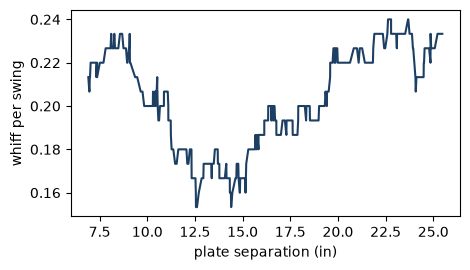

In [5]:
sw = scored[scored['swing']].sort_values('plate_sep_in')
fig, ax = plt.subplots(figsize=(4.8, 2.8))
ax.plot(sw['plate_sep_in'], sw['whiff'].astype(float).rolling(150, center=True).mean(), color='#1d3f63')
ax.set_xlabel('plate separation (in)'); ax.set_ylabel('whiff per swing'); fig.tight_layout(); plt.show()

In [6]:
from pathlib import Path
p = Path('../reports/effect_contrasts.csv')
if p.exists():
    t = pd.read_csv(p)
    print(t[t['sample'] == 'rows with a lag-2 pitch'].round(2).to_string(index=False))
else:
    print('run: tunneling effects --placebo')

outcome       feature    p10   p90  effect_pp  ci_lo_pp  ci_hi_pp  lag                  sample
  whiff commit_sep_in   3.10 15.36       0.12     -0.39      0.79    1 rows with a lag-2 pitch
  whiff  plate_sep_in   6.04 29.88      -1.27     -1.97     -0.69    1 rows with a lag-2 pitch
  whiff velo_diff_mph -10.30 10.00       4.70      2.81      5.82    1 rows with a lag-2 pitch
  whiff commit_sep_in   3.06 15.19      -0.55     -0.95      0.10    2 rows with a lag-2 pitch
  whiff  plate_sep_in   5.91 28.85       0.42     -0.27      0.78    2 rows with a lag-2 pitch
  whiff velo_diff_mph -10.40 10.00       5.14      3.21      6.55    2 rows with a lag-2 pitch
  chase commit_sep_in   3.77 18.74     -12.96    -13.84    -11.14    1 rows with a lag-2 pitch
  chase  plate_sep_in   7.63 37.08       7.72      6.03      9.08    1 rows with a lag-2 pitch
  chase velo_diff_mph  -9.90 10.50      -0.61     -2.99      1.88    1 rows with a lag-2 pitch
  chase commit_sep_in   3.78 18.76     -14.10    -

Each row is the change in an outcome rate when a feature moves from its 10th to its 90th percentile, everything else held at what was observed. `lag 1` uses the previous pitch; `lag 2` uses the pitch before that, on the same rows, as a placebo. If an effect belongs to tunneling, `lag 1` should be larger than `lag 2`.